In [ ]:
"""
BCSE331P - Exploratory Data Analysis
Assessment 3: Data Cleaning and Univariate Analysis
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
CSV_PATH = "orange_juice_withmissing.csv"

In [2]:
# 1. Import
df = pd.read_csv(CSV_PATH)

In [3]:
# 2. First and last six records
print("2. First six:\n", df.head(6), "\n")
print("   Last six:\n", df.tail(6), "\n")

2. First six:
   Purchase  WeekofPurchase  StoreID  PriceCH  PriceMM  DiscCH  DiscMM  \
0       CH             237      1.0     1.75     1.99    0.00     0.0   
1       CH             239      1.0     1.75     1.99    0.00     0.3   
2       CH             245      1.0     1.86     2.09    0.17     0.0   
3       MM             227      1.0     1.69     1.69    0.00     0.0   
4       CH             228      7.0     1.69     1.69    0.00     0.0   
5       CH             230      7.0     1.69     1.99    0.00     0.0   

   SpecialCH  SpecialMM   LoyalCH  SalePriceMM  SalePriceCH  PriceDiff Store7  \
0        0.0        0.0  0.500000         1.99         1.75       0.24     No   
1        0.0        1.0  0.600000         1.69         1.75      -0.06     No   
2        0.0        0.0  0.680000         2.09         1.69       0.40     No   
3        0.0        0.0  0.400000         1.69         1.69       0.00     No   
4        0.0        0.0  0.956535         1.69         1.69       0.

In [4]:
# 3. Total missing values
print("3. Total missing values:", int(df.isna().sum().sum()), "\n")

3. Total missing values: 40 



In [5]:
# 4. Records with at least one missing value
na_rows = df[df.isna().any(axis=1)]
print(f"4. Records with missing values ({len(na_rows)}):\n", na_rows.head(10), "\n")

4. Records with missing values (38):
     Purchase  WeekofPurchase  StoreID  PriceCH  PriceMM  DiscCH  DiscMM  \
60        CH             260      4.0     1.99     2.09     0.0     0.0   
97        CH             227      2.0     1.69     1.69     0.0     0.0   
139       CH             242      3.0     1.99     2.23     0.0     0.0   
182       CH             251      4.0     1.99     2.23     0.0     0.0   
183       CH             254      4.0     1.99     2.29     0.0     0.0   
212       CH             260      7.0     1.86     2.13     0.0     NaN   
226       MM             242      3.0     1.99     2.23     0.0     0.0   
245       CH             262      NaN     1.86     2.13     0.0     0.0   
271       MM             276      3.0     2.09     2.09     0.2     0.4   
275       MM             239      3.0     1.79     2.23     NaN     0.0   

     SpecialCH  SpecialMM   LoyalCH  SalePriceMM  SalePriceCH  PriceDiff  \
60         0.0        0.0       NaN         2.09         1.9

In [6]:
# 5. Remove columns with more than 70 % missing
pct_missing = df.isna().mean() * 100
drop_cols = pct_missing[pct_missing > 70].index.tolist()
df = df.drop(columns=drop_cols)
print("5. Columns dropped (>70% missing):", drop_cols or "None", "\n")

num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

5. Columns dropped (>70% missing): None 



In [7]:
# 6. Mean imputation (shown on a copy)
df_mean = df.copy()
df_mean[num_cols] = df_mean[num_cols].fillna(df_mean[num_cols].mean())
print("6. Missing after mean imputation:", int(df_mean[num_cols].isna().sum().sum()))

6. Missing after mean imputation: 0


In [8]:
# 7. Median imputation (used for the working dataset)
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
print("7. Missing after median imputation:", int(df[num_cols].isna().sum().sum()))

7. Missing after median imputation: 0


In [9]:
# 8. Mode imputation for categorical columns
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])
print("8. Missing after mode imputation (categorical):", int(df[cat_cols].isna().sum().sum()), "\n")

8. Missing after mode imputation (categorical): 0 



In [10]:
# 9-10. Duplicates
print("9. Duplicate rows:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)
print("10. Shape after removing duplicates:", df.shape, "\n")

9. Duplicate rows: 25
10. Shape after removing duplicates: (1045, 18) 



In [11]:
# 11. Columns with incorrect data types
#     StoreID / STORE are identifiers, SpecialCH / SpecialMM are 0/1 flags -> should be categorical
print("11. Current dtypes:\n", df.dtypes)
print("    Likely incorrect: StoreID, STORE, SpecialCH, SpecialMM (codes stored as numbers)\n")

11. Current dtypes:
 Purchase              str
WeekofPurchase      int64
StoreID           float64
PriceCH           float64
PriceMM           float64
DiscCH            float64
DiscMM            float64
SpecialCH         float64
SpecialMM         float64
LoyalCH           float64
SalePriceMM       float64
SalePriceCH       float64
PriceDiff         float64
Store7                str
PctDiscMM         float64
PctDiscCH         float64
ListPriceDiff     float64
STORE             float64
dtype: object
    Likely incorrect: StoreID, STORE, SpecialCH, SpecialMM (codes stored as numbers)



In [12]:
# 12. Convert character variables to factors (category)
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype("category")
for c in ["StoreID", "STORE", "SpecialCH", "SpecialMM"]:
    df[c] = df[c].astype(int).astype("category")
print("12. dtypes after conversion:\n", df.dtypes, "\n")

12. dtypes after conversion:
 Purchase          category
WeekofPurchase       int64
StoreID           category
PriceCH            float64
PriceMM            float64
DiscCH             float64
DiscMM             float64
SpecialCH         category
SpecialMM         category
LoyalCH            float64
SalePriceMM        float64
SalePriceCH        float64
PriceDiff          float64
Store7            category
PctDiscMM          float64
PctDiscCH          float64
ListPriceDiff      float64
STORE             category
dtype: object 



In [13]:
# 13. Lowercase / uppercase
df["Purchase_lower"] = df["Purchase"].astype(str).str.lower()
df["Store7_upper"] = df["Store7"].astype(str).str.upper()
print("13. Case conversion:\n", df[["Purchase", "Purchase_lower", "Store7", "Store7_upper"]].head(), "\n")

13. Case conversion:
   Purchase Purchase_lower Store7 Store7_upper
0       CH             ch     No           NO
1       CH             ch     No           NO
2       CH             ch     No           NO
3       MM             mm     No           NO
4       CH             ch    Yes          YES 



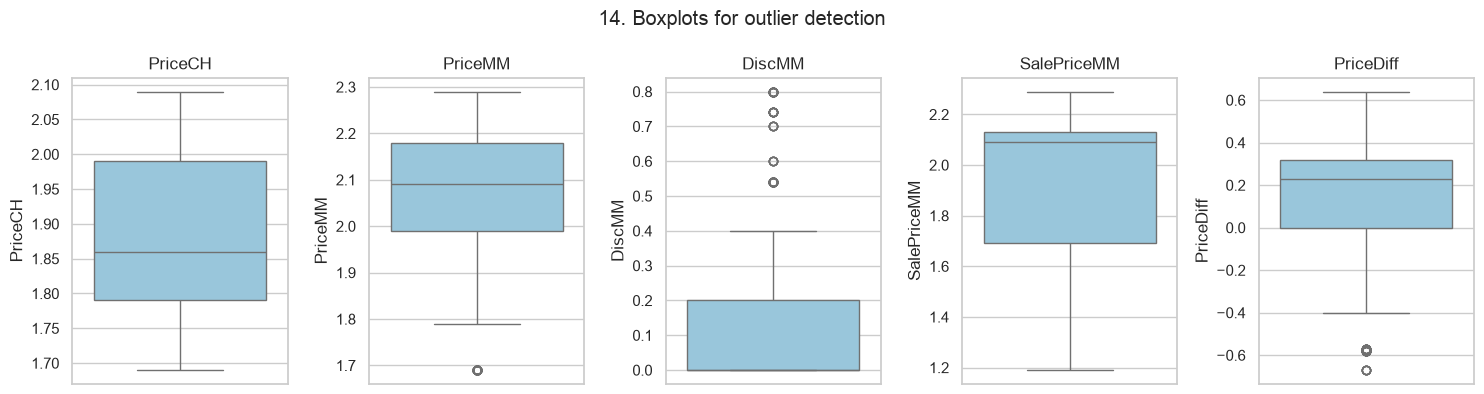

In [14]:
# 14. Outlier detection using boxplots
out_cols = ["PriceCH", "PriceMM", "DiscMM", "SalePriceMM", "PriceDiff"]
fig, ax = plt.subplots(1, len(out_cols), figsize=(15, 4))
for a, c in zip(ax, out_cols):
    sns.boxplot(y=df[c], ax=a, color="#8ecae6")
    a.set_title(c)
fig.suptitle("14. Boxplots for outlier detection")
plt.tight_layout(); plt.show()

In [15]:
# 15. IQR method
outlier_summary = {}
for c in out_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[c] = int(((df[c] < lo) | (df[c] > hi)).sum())
print("15. Outliers per column (IQR method):", outlier_summary, "\n")

15. Outliers per column (IQR method): {'PriceCH': 0, 'PriceMM': 55, 'DiscMM': 84, 'SalePriceMM': 0, 'PriceDiff': 34} 



In [16]:
# 16. Remove extreme outliers (3 x IQR rule)
mask = pd.Series(True, index=df.index)
for c in out_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    mask &= df[c].between(q1 - 3 * iqr, q3 + 3 * iqr)
df_no_out = df[mask].reset_index(drop=True)
print(f"16. Rows before: {len(df)}, after removing extreme outliers: {len(df_no_out)}\n")

16. Rows before: 1045, after removing extreme outliers: 1045



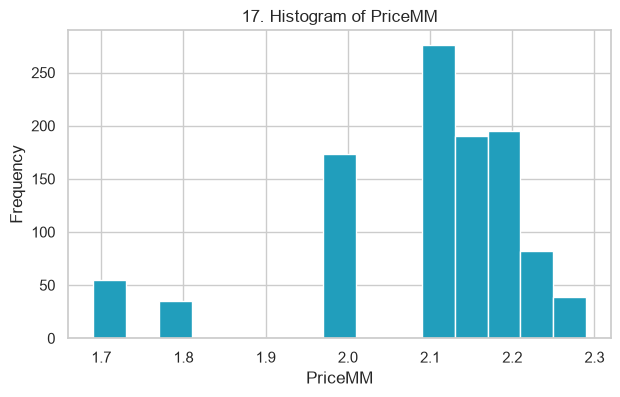

17. Interpretation: skewness = -1.464 -> a value near 0 is symmetric; >0 right-skewed, <0 left-skewed.



In [17]:
# 17. Histogram + interpretation
plt.figure(figsize=(7, 4))
plt.hist(df_no_out["PriceMM"], bins=15, color="#219ebc", edgecolor="white")
plt.title("17. Histogram of PriceMM"); plt.xlabel("PriceMM"); plt.ylabel("Frequency")
plt.show()
print("17. Interpretation: skewness =", round(df_no_out["PriceMM"].skew(), 3),
      "-> a value near 0 is symmetric; >0 right-skewed, <0 left-skewed.\n")

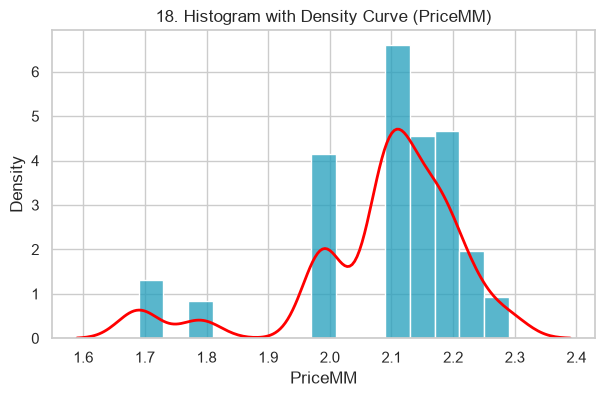

In [18]:
# 18. Histogram with density curve
plt.figure(figsize=(7, 4))
sns.histplot(df_no_out["PriceMM"], bins=15, stat="density", color="#219ebc", edgecolor="white")
sns.kdeplot(df_no_out["PriceMM"], color="red", linewidth=2)
plt.title("18. Histogram with Density Curve (PriceMM)")
plt.show()

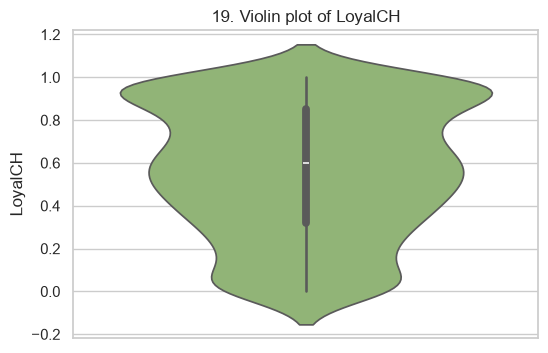

In [19]:
# 19. Violin plot
plt.figure(figsize=(6, 4))
sns.violinplot(y=df_no_out["LoyalCH"], color="#90be6d")
plt.title("19. Violin plot of LoyalCH")
plt.show()

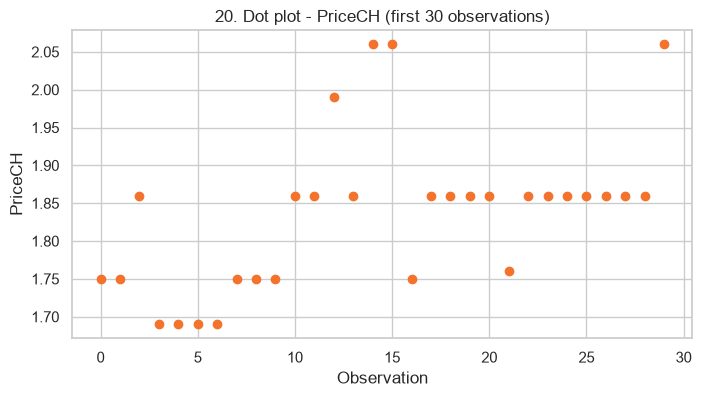

In [20]:
# 20. Dot plot for a small numeric dataset (first 30 observations)
small = df_no_out["PriceCH"].head(30).reset_index(drop=True)
plt.figure(figsize=(8, 4))
plt.plot(small.index, small.values, "o", color="#f3722c")
plt.title("20. Dot plot - PriceCH (first 30 observations)")
plt.xlabel("Observation"); plt.ylabel("PriceCH")
plt.show()

In [21]:
# 21. Frequency table
freq = df_no_out["STORE"].value_counts().sort_index()
print("21. Frequency table (STORE):\n", freq, "\n")

21. Frequency table (STORE):
 STORE
0    343
1    154
2    221
3    190
4    137
Name: count, dtype: int64 



In [22]:
# 22. Proportion and percentage
prop = freq / freq.sum()
table = pd.DataFrame({"Frequency": freq, "Proportion": prop.round(4), "Percentage": (prop * 100).round(2)})
print("22. Proportion & percentage:\n", table, "\n")

22. Proportion & percentage:
        Frequency  Proportion  Percentage
STORE                                   
0            343      0.3282       32.82
1            154      0.1474       14.74
2            221      0.2115       21.15
3            190      0.1818       18.18
4            137      0.1311       13.11 



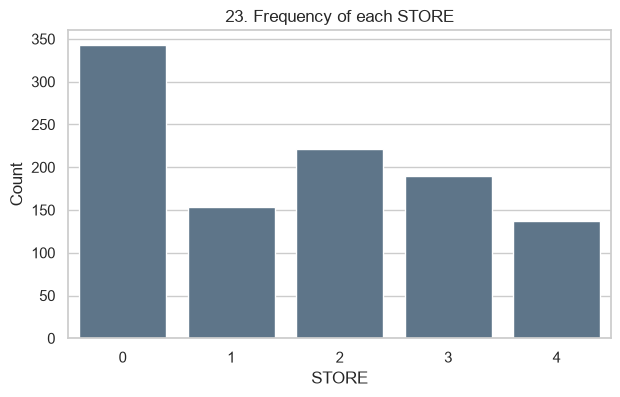

In [23]:
# 23. Bar chart (frequency)
plt.figure(figsize=(7, 4))
sns.barplot(x=freq.index.astype(str), y=freq.values, color="#577590")
plt.title("23. Frequency of each STORE"); plt.xlabel("STORE"); plt.ylabel("Count")
plt.show()

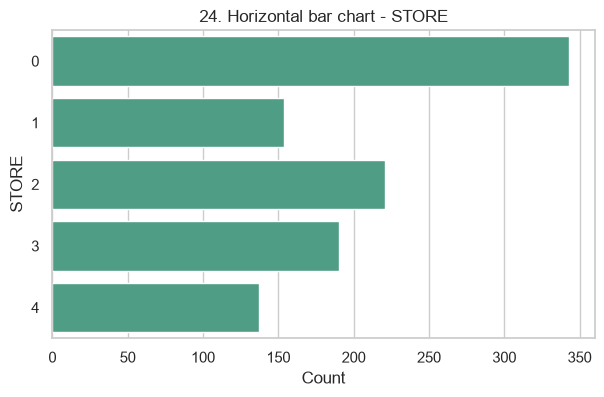

In [24]:
# 24. Horizontal bar chart
plt.figure(figsize=(7, 4))
sns.barplot(y=freq.index.astype(str), x=freq.values, color="#43aa8b", orient="h")
plt.title("24. Horizontal bar chart - STORE"); plt.xlabel("Count"); plt.ylabel("STORE")
plt.show()

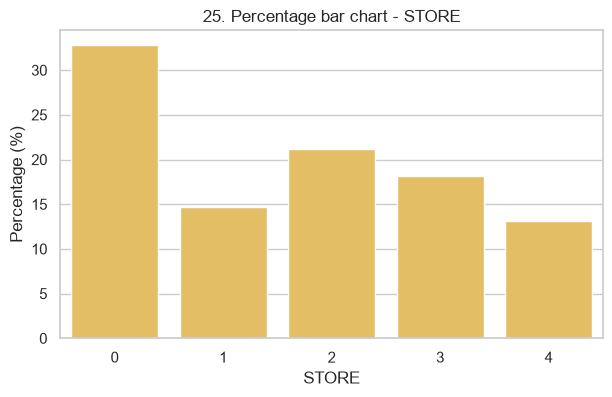

In [25]:
# 25. Percentage bar chart
plt.figure(figsize=(7, 4))
sns.barplot(x=table.index.astype(str), y=table["Percentage"], color="#f9c74f")
plt.title("25. Percentage bar chart - STORE"); plt.xlabel("STORE"); plt.ylabel("Percentage (%)")
plt.show()

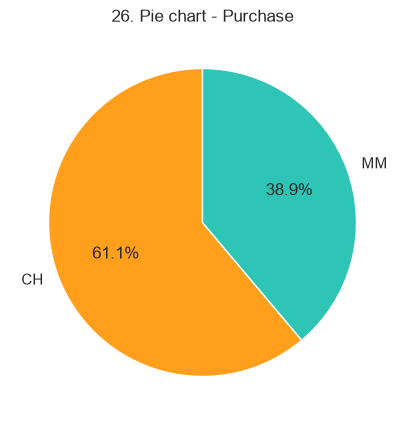

In [26]:
# 26. Pie chart (small number of categories)
pur = df_no_out["Purchase"].value_counts()
plt.figure(figsize=(5, 5))
plt.pie(pur.values, labels=pur.index, autopct="%1.1f%%", colors=["#ff9f1c", "#2ec4b6"], startangle=90)
plt.title("26. Pie chart - Purchase")
plt.show()

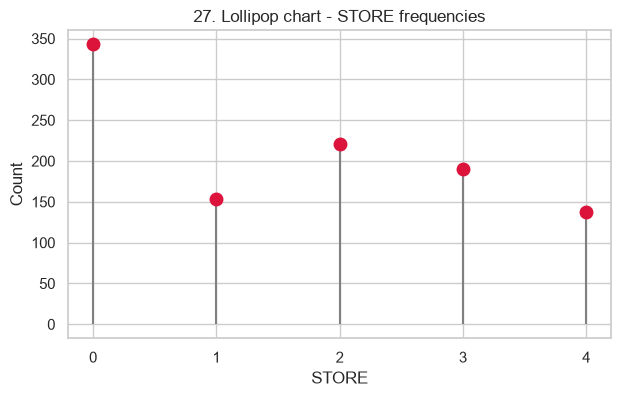

In [27]:
# 27. Lollipop chart
plt.figure(figsize=(7, 4))
plt.vlines(x=range(len(freq)), ymin=0, ymax=freq.values, color="grey")
plt.plot(range(len(freq)), freq.values, "o", color="crimson", markersize=9)
plt.xticks(range(len(freq)), freq.index.astype(str))
plt.title("27. Lollipop chart - STORE frequencies"); plt.xlabel("STORE"); plt.ylabel("Count")
plt.show()

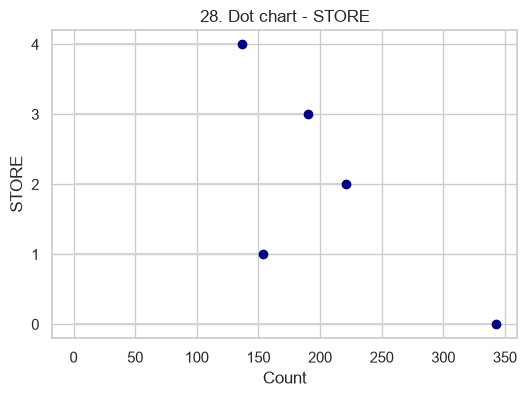

In [28]:
# 28. Dot chart (Cleveland style)
plt.figure(figsize=(6, 4))
plt.hlines(y=range(len(freq)), xmin=0, xmax=freq.values, color="lightgrey")
plt.plot(freq.values, range(len(freq)), "o", color="navy")
plt.yticks(range(len(freq)), freq.index.astype(str))
plt.title("28. Dot chart - STORE"); plt.xlabel("Count"); plt.ylabel("STORE")
plt.show()

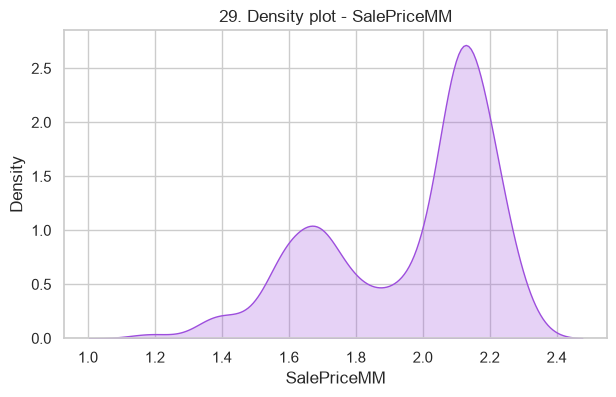

In [29]:
# 29. Density plot
plt.figure(figsize=(7, 4))
sns.kdeplot(df_no_out["SalePriceMM"], fill=True, color="#9d4edd")
plt.title("29. Density plot - SalePriceMM")
plt.show()

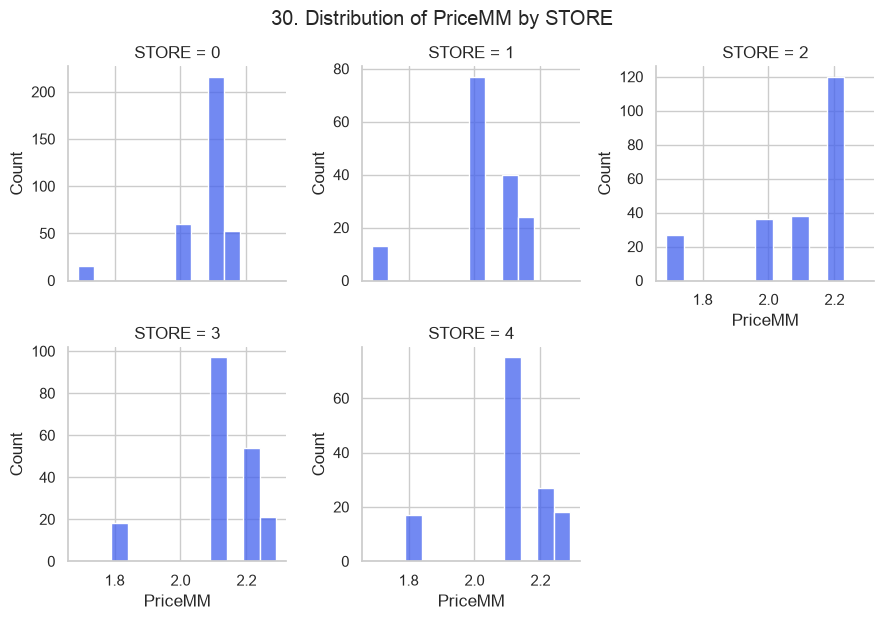

STORE 0: mean PriceMM=2.089, median=2.130, skew=-2.51
STORE 1: mean PriceMM=2.025, median=1.990, skew=-1.25
STORE 2: mean PriceMM=2.074, median=2.180, skew=-1.58
STORE 3: mean PriceMM=2.123, median=2.090, skew=-1.18
STORE 4: mean PriceMM=2.107, median=2.090, skew=-0.99
Interpretation: compare centre (mean/median) and skew across stores to see whether pricing is consistent or shifted for particular stores.


In [30]:
# 30. facet_wrap equivalent: distribution of one variable across groups
g = sns.FacetGrid(df_no_out, col="STORE", col_wrap=3, height=3, sharey=False)
g.map(sns.histplot, "PriceMM", bins=10, color="#4361ee")
g.fig.suptitle("30. Distribution of PriceMM by STORE", y=1.03)
plt.show()
for s, grp in df_no_out.groupby("STORE", observed=True):
    print(f"STORE {s}: mean PriceMM={grp['PriceMM'].mean():.3f}, "
          f"median={grp['PriceMM'].median():.3f}, skew={grp['PriceMM'].skew():.2f}")
print("Interpretation: compare centre (mean/median) and skew across stores to see "
      "whether pricing is consistent or shifted for particular stores.")